<a href="https://colab.research.google.com/github/peter-adepoju/math-neuro-ml/blob/main/week4/lesson12/Lesson12_Teaching_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **MAMBA: Mathematical Sciences for Brain Data**
## Lesson 12 — One-Dimensional Gradient Descent: Learning One Step at a Time

**Course:** MAMBA: Mathematical Sciences for Brain Data\
**Week:** Week 4 — Calculus II\
**Lesson:** Lesson 12\
**Notebook type:** Teaching notebook

> *"Learning is walking downhill in the dark: feel the slope under your feet, take a step, and feel again. How long the steps should be is the whole art."*

---

### From knowing where the bottom is to getting there

Lesson 11 described the bottoms of valleys: where the slope is zero, how curved the valley is, and whether there is only one. It did not say how to **reach** the bottom when no formula gives it directly, which is the usual situation for neural networks, nonlinear tuning curves, and most models worth fitting.

**Gradient descent** reaches it by repetition: look at the slope where you are, take a small step downhill, and repeat. This lesson studies the rule in one dimension, where every behaviour can be seen and understood: how the **learning rate** decides between slow progress, fast convergence, oscillation and explosion; how the **starting point** and the **stopping rule** shape the answer; and what happens when the slope is only **estimated** from a random handful of data points (**stochastic** gradient descent), as in almost all of modern machine learning. The mini-lab fits how strongly a motor-cortex neuron's spiking depends on hand movement, and shows that a learning rate which is safe at the start of training can trap the fit in an endless oscillation near the end.

### Import Dependencies

In [1]:
# SETUP CELL
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go

RNG = np.random.default_rng(42)

# The same colourblind-conscious palette and markers as Lessons 1-11.
PALETTE = ['#0072B2', '#D55E00', '#009E73', '#CC79A7', '#E69F00', '#56B4E9']
MARKERS = ['o', 's', '^', 'D', 'v', 'P']

print("Setup complete.")

Setup complete.


### Interactive and animated plotting tools

As before, each static figure is followed by a **Plotly version** that you can zoom, pan, hover over, and save. Several have sliders: drag them, or press **Play**.

In [2]:
# INTERACTIVE/ANIMATION SETUP
import sys
import plotly.io as pio

if 'google.colab' not in sys.modules:
    pio.renderers.default = 'notebook_connected'
pio.templates['plotly_white'].layout.xaxis.showgrid = False
pio.templates['plotly_white'].layout.yaxis.showgrid = False

PLOTLY_CONFIG = {'displaylogo': False, 'responsive': True, 'scrollZoom': True,
                 'toImageButtonOptions': {'format': 'png', 'scale': 2}}

def play_pause_and_slider(labels, prefix, duration=150):
    # Play/Pause buttons and a frame slider, as used in Lessons 1-11.
    buttons = [dict(
        type='buttons', showactive=False, x=0.0, y=-0.12, xanchor='left', yanchor='top',
        buttons=[
            dict(label='Play', method='animate', args=[None, {'frame': {'duration': duration, 'redraw': True}, 'transition': {'duration': 0}, 'fromcurrent': True}]),
            dict(label='Pause', method='animate', args=[[None], {'frame': {'duration': 0, 'redraw': False}, 'mode': 'immediate'}]),
        ],
    )]
    sliders = [dict(
        active=0, currentvalue={'prefix': prefix}, pad={'t': 50},
        steps=[dict(label=str(lab), method='animate', args=[[str(k)], {'mode': 'immediate', 'frame': {'duration': 0, 'redraw': True}, 'transition': {'duration': 0}}])
               for k, lab in enumerate(labels)],
    )]
    return buttons, sliders

def gradient_descent(grad, theta0, eta, n_steps):
    # The update rule of this lesson: theta <- theta - eta * dL/dtheta. Returns the whole path, shape (n_steps + 1,).
    path = [theta0]
    for _ in range(n_steps):
        path.append(path[-1] - eta * grad(path[-1]))
    return np.array(path)

print('Interactive plotting and animation tools are ready.')

Interactive plotting and animation tools are ready.


# **Motivation: a synapse that learns from its errors**

A model neuron receives an input $x$ (a stimulus feature, in standardised units) through a synapse of strength $w$ and should produce a target rate $y$ (spikes/s). Its prediction is $\hat y = wx$. A classic learning rule, the **delta rule** (Widrow and Hoff, 1960), changes the weight after each trial in proportion to the error and the input:

$$w \leftarrow w + \eta\,(y - wx)\,x .$$

This is gradient descent. The squared error $L(w) = \tfrac12(y - wx)^2$ has slope $L'(w) = -(y - wx)\,x$, so the rule is exactly $w \leftarrow w - \eta L'(w)$: a step downhill whose size is set by the **learning rate** $\eta$. The same idea, with prediction errors about rewards, is the Rescorla–Wagner model of conditioning and the core of reinforcement-learning accounts of dopamine.

Below, a simulated neuron learns a true weight of 2.5 from 200 noisy trials, with three learning rates.

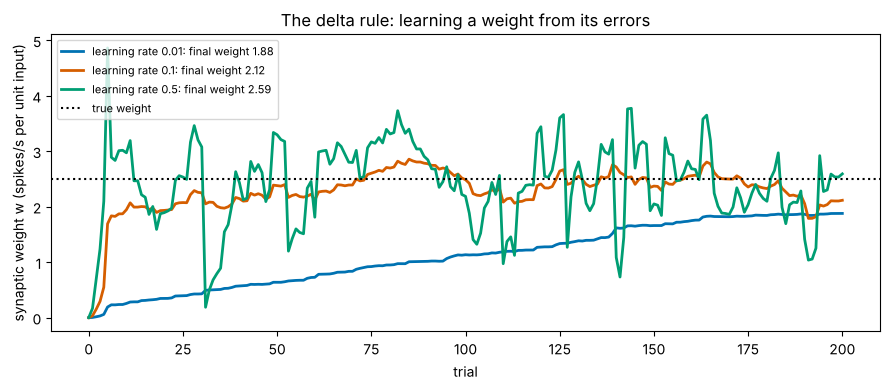

In [3]:
n_trials = 200
x_tr = RNG.normal(size=n_trials)                           # (200,) input on each trial, standardised units
y_tr = 2.5 * x_tr + RNG.normal(0, 1.0, n_trials)            # (200,) target rate, spikes/s (true weight 2.5)

fig, ax = plt.subplots(figsize=(9, 4))
for eta, colour in zip([0.01, 0.1, 0.5], PALETTE):
    w = 0.0; ws = [w]
    for x_k, y_k in zip(x_tr, y_tr):
        w = w + eta * (y_k - w * x_k) * x_k                  # the delta rule: one trial at a time
        ws.append(w)
    ax.plot(ws, color=colour, lw=2, label=f'learning rate {eta}: final weight {w:.2f}')
ax.axhline(2.5, color='black', ls=':', label='true weight')
ax.set_xlabel('trial'); ax.set_ylabel('synaptic weight w (spikes/s per unit input)'); ax.set_title('The delta rule: learning a weight from its errors'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

A small learning rate learns slowly but settles smoothly; a large one learns fast but keeps jumping around, because each trial's error is noisy. This trade-off between **speed** and **stability**, and the role of **noise**, are the subject of this lesson.

# **Part 1: The Update Rule**

To minimise a loss $L(\theta)$ of one parameter $\theta$, start from a guess $\theta_0$ and repeat

$$\boxed{\theta_{k+1} = \theta_k - \eta\,\frac{dL}{d\theta}(\theta_k)}\qquad k = 0, 1, 2, \dots$$

with a **learning rate** (step size) $\eta > 0$.

**Why it goes downhill.** By the linear approximation (Lesson 9), a step $h$ changes the loss by about $L'(\theta)\,h$. With $h = -\eta L'(\theta)$,

$$L(\theta_{k+1}) \approx L(\theta_k) - \eta\,L'(\theta_k)^2 \;\le\; L(\theta_k).$$

The loss decreases whenever the slope is not zero, **provided the step is small enough** for the linear approximation to hold. When the slope is zero, the rule stops moving: gradient descent can only stop at critical points (Lesson 11).

**Units.** If $\theta$ is in units $u$ and $L$ in units $\ell$, then $L'$ is in $\ell/u$ and the step $\eta L'$ must be in $u$, so $\eta$ has units $u^2/\ell$. A learning rate is not a pure number: rescaling the parameter or the loss changes the right value of $\eta$.

**The batch version.** With $n$ trials the loss is usually the **average**, $L(w) = \frac{1}{2n}\sum_i (y_i - wx_i)^2$, and the gradient is the average of the per-trial gradients: $L'(w) = -\frac1n\sum_i (y_i - wx_i)\,x_i$. Full-batch gradient descent uses all trials at every step; the delta rule above used one trial per step (Part 4).

exact minimiser w* = 2.4181
step  0: w = -1.0000, loss = 5.0412, slope = -2.6485
step  1: w = -0.2054, loss = 3.1814, slope = -2.0329
step  2: w = +0.4044, loss = 2.0857, slope = -1.5603
step  3: w = +0.8725, loss = 1.4402, slope = -1.1976
step  5: w = +1.5076, loss = 0.8359, slope = -0.7055
step 10: w = +2.1756, loss = 0.5375, slope = -0.1880
step 15: w = +2.3535, loss = 0.5163, slope = -0.0501


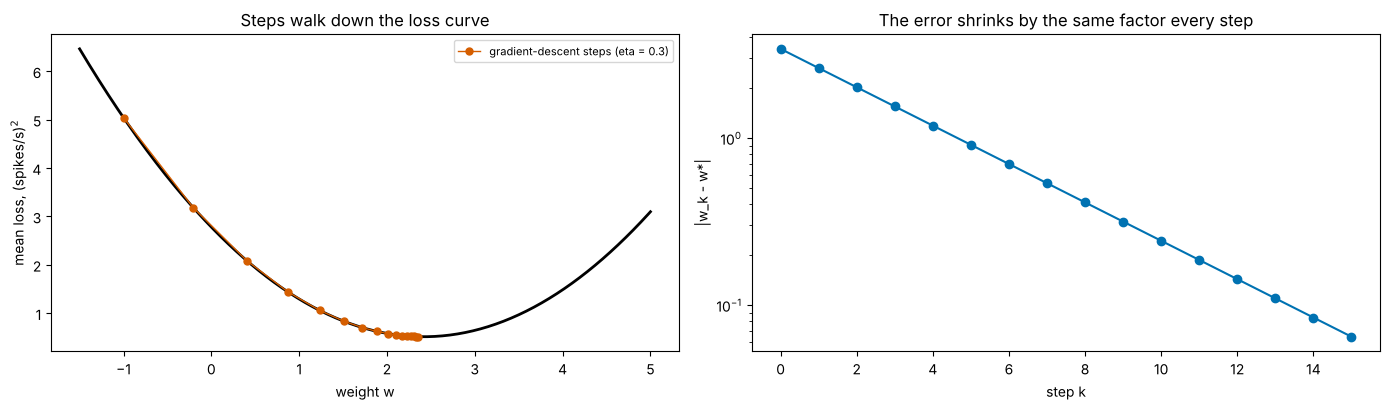

In [4]:
def L_gain(w):
    return 0.5 * np.mean((y_tr - w * x_tr)**2)              # (spikes/s)^2
def dL_gain(w):
    return -np.mean((y_tr - w * x_tr) * x_tr)                # (spikes/s)^2 per unit weight

w_star = np.sum(x_tr * y_tr) / np.sum(x_tr**2)               # exact minimiser (Lesson 5, one-variable least squares)
path = gradient_descent(dL_gain, theta0=-1.0, eta=0.3, n_steps=15)
print(f"exact minimiser w* = {w_star:.4f}")
for k in [0, 1, 2, 3, 5, 10, 15]:
    print(f"step {k:2d}: w = {path[k]:+.4f}, loss = {L_gain(path[k]):.4f}, slope = {dL_gain(path[k]):+.4f}")

ws_grid = np.linspace(-1.5, 5, 300)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
axes[0].plot(ws_grid, [L_gain(v) for v in ws_grid], color='black', lw=2)
axes[0].plot(path, [L_gain(v) for v in path], 'o-', color=PALETTE[1], ms=5, lw=1, label='gradient-descent steps (eta = 0.3)')
axes[0].set_xlabel('weight w'); axes[0].set_ylabel('mean loss, (spikes/s)$^2$'); axes[0].set_title('Steps walk down the loss curve'); axes[0].legend(fontsize=8)
axes[1].semilogy(np.abs(path - w_star) + 1e-16, 'o-', color=PALETTE[0])
axes[1].set_xlabel('step k'); axes[1].set_ylabel('|w_k - w*|'); axes[1].set_title('The error shrinks by the same factor every step')
plt.tight_layout(); plt.show()

#### Interactive version: watch the steps

In [5]:
path_anim = gradient_descent(dL_gain, theta0=-1.0, eta=0.3, n_steps=20)
loss_curve = np.array([L_gain(v) for v in ws_grid])
fig_s = go.Figure([go.Scatter(x=ws_grid, y=np.round(loss_curve, 4), mode='lines', line=dict(color='black', width=3), name='loss'),
                   go.Scatter(x=path_anim[:1], y=[L_gain(path_anim[0])], mode='lines+markers', marker=dict(size=9, color=PALETTE[1]), line=dict(color=PALETTE[1]), name='steps')])
fig_s.frames = [go.Frame(name=str(k), traces=[1], data=[go.Scatter(x=np.round(path_anim[:k + 1], 4), y=np.round([L_gain(v) for v in path_anim[:k + 1]], 4))],
                         layout=go.Layout(title=f'step {k}: w = {path_anim[k]:.3f}, slope = {dL_gain(path_anim[k]):+.3f}')) for k in range(len(path_anim))]
buttons, sliders = play_pause_and_slider(list(range(len(path_anim))), prefix='step = ', duration=400)
fig_s.update_layout(title=fig_s.frames[0].layout.title.text, xaxis_title='weight w', yaxis_title='mean loss', template='plotly_white',
                    width=850, height=460, updatemenus=buttons, sliders=sliders)
fig_s.show(config=PLOTLY_CONFIG)

# **Part 2: The Convex Quadratic — Learning Rate and Convergence**

The cleanest case is a convex quadratic with curvature $a > 0$ and minimum at $\theta^*$:

$$L(\theta) = \tfrac{a}{2}(\theta - \theta^*)^2,\qquad L'(\theta) = a(\theta - \theta^*).$$

The squared-error loss of Part 1 has exactly this form, with $a = \frac1n\sum x_i^2$. Writing the error as $e_k = \theta_k - \theta^*$, one step gives

$$e_{k+1} = e_k - \eta a e_k = (1 - \eta a)\,e_k \quad\Longrightarrow\quad e_k = (1 - \eta a)^k e_0 .$$

Everything depends on the **contraction factor** $q = 1 - \eta a$:

| Learning rate | $q = 1 - \eta a$ | Behaviour |
|---|---|---|
| $0 < \eta < 1/a$ | $0 < q < 1$ | creeps monotonically towards $\theta^*$ |
| $\eta = 1/a$ | $q = 0$ | lands on $\theta^*$ in **one** step (Newton's step, Lesson 11) |
| $1/a < \eta < 2/a$ | $-1 < q < 0$ | overshoots, oscillates, but converges |
| $\eta = 2/a$ | $q = -1$ | bounces between $\theta^* \pm e_0$ forever |
| $\eta > 2/a$ | $q < -1$ | oscillates with growing amplitude: **diverges** |

**The stability limit $\eta < 2/a$** is the most important fact of this lesson: the largest usable learning rate is set by the **curvature**. Sharp valleys (large $a$) need small steps. Since any smooth loss looks like a parabola near its minimum (Lesson 11), the local curvature $L''(\theta^*)$ plays the role of $a$ for every loss.

**How many steps?** To shrink the error by a factor of $\varepsilon$ takes about $k \approx \ln\varepsilon/\ln|q|$ steps. With $\eta a = 0.1$, $|q| = 0.9$, so shrinking the error a million-fold takes about 131 steps; with $\eta a = 0.01$, about 1375. This is **linear convergence**: a fixed number of correct digits per step.

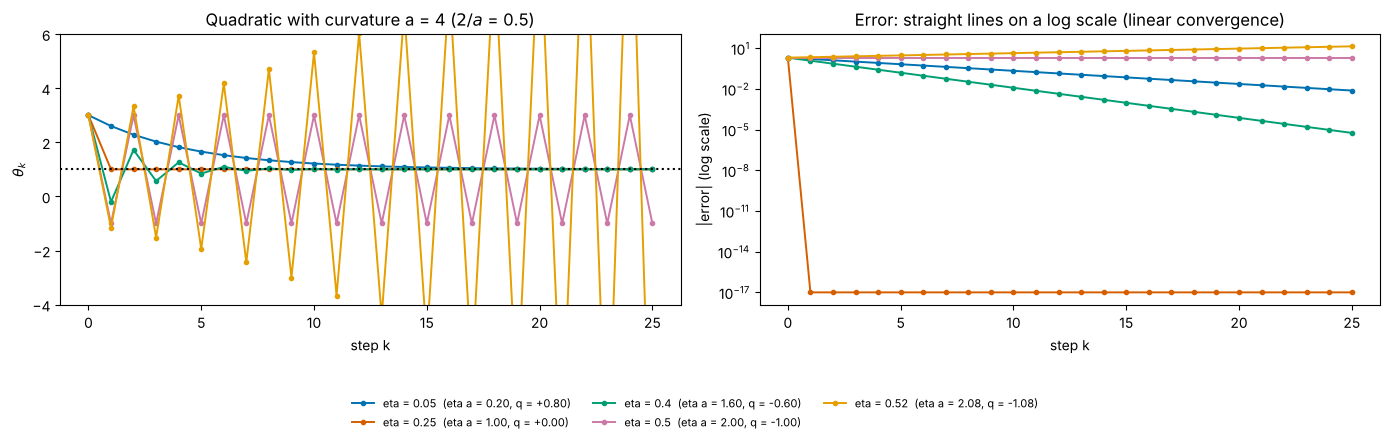

steps to shrink the error 10^6-fold: eta = 0.025 -> 131, eta = 0.125 -> 20, eta = 0.25 -> 1 (exactly), eta = 0.45 -> 62


In [6]:
a_q, theta_star_q = 4.0, 1.0
dL_q = lambda th: a_q * (th - theta_star_q)
etas_q = [0.05, 0.25, 0.4, 0.5, 0.52]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
for eta, colour in zip(etas_q, PALETTE):
    p = gradient_descent(dL_q, 3.0, eta, 25)
    axes[0].plot(p, 'o-', ms=3, lw=1.4, color=colour, label=f'eta = {eta}  (eta a = {eta * a_q:.2f}, q = {1 - eta * a_q:+.2f})')
    axes[1].semilogy(np.abs(p - theta_star_q) + 1e-17, 'o-', ms=3, lw=1.4, color=colour)
axes[0].axhline(theta_star_q, color='black', ls=':'); axes[0].set_ylim(-4, 6)
axes[0].set_xlabel('step k'); axes[0].set_ylabel('$\\theta_k$'); axes[0].set_title('Quadratic with curvature a = 4 ($2/a$ = 0.5)')
axes[1].set_xlabel('step k'); axes[1].set_ylabel('|error| (log scale)'); axes[1].set_title('Error: straight lines on a log scale (linear convergence)')
fig.legend(*axes[0].get_legend_handles_labels(), loc='lower center', ncol=3, fontsize=8, frameon=False)
plt.tight_layout(rect=[0, 0.15, 1, 1]); plt.show()

etas_scan = np.linspace(0.004, 0.496, 124)                  # avoids eta a = 1 exactly (zero steps)
steps_needed = np.log(1e-6) / np.log(np.abs(1 - etas_scan * a_q))
print(f"steps to shrink the error 10^6-fold: eta = 0.025 -> {np.log(1e-6) / np.log(abs(1 - 0.025 * a_q)):.0f}, eta = 0.125 -> {np.log(1e-6) / np.log(abs(1 - 0.125 * a_q)):.0f}, "
      f"eta = 0.25 -> 1 (exactly), eta = 0.45 -> {np.log(1e-6) / np.log(abs(1 - 0.45 * a_q)):.0f}")

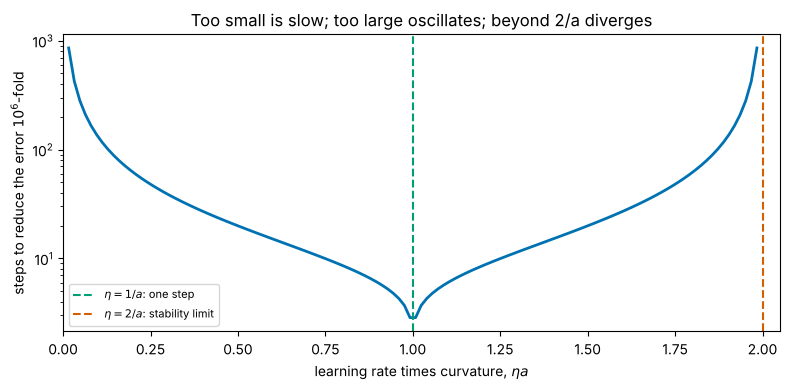

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.semilogy(etas_scan * a_q, steps_needed, color=PALETTE[0], lw=2)
ax.axvline(1, color=PALETTE[2], ls='--', label='$\\eta = 1/a$: one step')
ax.axvline(2, color=PALETTE[1], ls='--', label='$\\eta = 2/a$: stability limit')
ax.set_xlabel('learning rate times curvature, $\\eta a$'); ax.set_ylabel('steps to reduce the error $10^6$-fold'); ax.set_xlim(0, 2.05)
ax.set_title('Too small is slow; too large oscillates; beyond 2/a diverges'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

#### Interactive version: drag the learning rate

In [8]:
etas_sl = np.round(np.linspace(0.02, 0.56, 28), 3)
th_grid = np.linspace(-4, 6, 200)
def path_xy(eta):
    p = gradient_descent(dL_q, 3.0, eta, 12)
    p = np.clip(p, -4, 6)
    return np.round(p, 4), np.round(0.5 * a_q * (p - theta_star_q)**2, 4)
px, py = path_xy(etas_sl[0])
fig_q = go.Figure([go.Scatter(x=th_grid, y=np.round(0.5 * a_q * (th_grid - theta_star_q)**2, 4), mode='lines', line=dict(color='black', width=3), name='L'),
                   go.Scatter(x=px, y=py, mode='lines+markers', marker=dict(size=8, color=PALETTE[1]), line=dict(color=PALETTE[1]), name='12 steps')])
fig_q.frames = [go.Frame(name=str(k), traces=[1], data=[go.Scatter(x=path_xy(e)[0], y=path_xy(e)[1])],
                         layout=go.Layout(title=f'eta = {e:.3f}: eta a = {e * a_q:.2f}, contraction factor q = {1 - e * a_q:+.2f}')) for k, e in enumerate(etas_sl)]
buttons, sliders = play_pause_and_slider(list(etas_sl), prefix='eta = ', duration=500)
fig_q.update_layout(title=fig_q.frames[0].layout.title.text, xaxis_title='theta', yaxis=dict(title='loss', range=[0, 52]), template='plotly_white',
                    width=850, height=460, updatemenus=buttons, sliders=sliders)
fig_q.show(config=PLOTLY_CONFIG)

# **Part 3: Initialisation, Iteration, Tolerance and Stopping**

A complete gradient-descent routine needs four decisions besides $\eta$:

1. **Initialisation** $\theta_0$: on a convex loss it changes only the time taken; on a non-convex loss it decides **which** minimum is found (Lesson 11).
2. **Iteration budget**: a maximum number of steps, so that the routine always ends.
3. **Tolerance and stopping rule**: when is the answer good enough? Common rules:
   - **gradient**: stop when $|L'(\theta_k)| < g_{\text{tol}}$ (the slope is nearly zero);
   - **step**: stop when $|\theta_{k+1} - \theta_k| < x_{\text{tol}}$ (the parameter has stopped moving);
   - **loss change**: stop when $|L(\theta_{k+1}) - L(\theta_k)| < f_{\text{tol}}$, often relative to $|L|$;
   - **validation**: stop when the loss on held-out data stops improving (**early stopping**, Lessons 10 and 15).
4. **Monitoring**: record $\theta_k$, $L(\theta_k)$ and $L'(\theta_k)$ along the way, and check for `nan` or growth.

Each stopping rule can be fooled. On a **flat-bottomed** loss such as $L = \theta^4/4$, the minimum at 0 has zero curvature, so steps shrink as the minimum is approached, and "the parameter has stopped moving" is declared long before it arrives. Tolerances have **units** too: $g_{\text{tol}}$ is in loss per parameter unit, $x_{\text{tol}}$ in parameter units.

In [9]:
def gd_with_stopping(grad, theta0, eta, max_iter=100000, gtol=None, xtol=None):
    # Gradient descent with optional gradient and step tolerances; returns (theta, number of steps, reason).
    theta = theta0
    for k in range(max_iter):
        g = grad(theta)
        if gtol is not None and abs(g) < gtol:
            return theta, k, 'gradient below gtol'
        step = eta * g
        theta = theta - step
        if not np.isfinite(theta):
            return theta, k + 1, 'diverged'
        if xtol is not None and abs(step) < xtol:
            return theta, k + 1, 'step below xtol'
    return theta, max_iter, 'max_iter reached'

flat_grad = lambda th: th**3                                 # L = theta^4 / 4: minimum at 0 with zero curvature
quad_grad = lambda th: th                                    # L = theta^2 / 2: curvature 1
print(f"{'loss':<14}{'rule':<16}{'final theta':>14}{'steps':>8}   reason")
for name, gfun in [('theta^4 / 4', flat_grad), ('theta^2 / 2', quad_grad)]:
    for rule, kw in [('xtol = 1e-3', dict(xtol=1e-3)), ('xtol = 1e-4', dict(xtol=1e-4)), ('gtol = 1e-6', dict(gtol=1e-6))]:
        th, k, why = gd_with_stopping(gfun, 1.0, 0.1, **kw)
        print(f"{name:<14}{rule:<16}{th:>14.6f}{k:>8}   {why}")

loss          rule               final theta   steps   reason
theta^4 / 4   xtol = 1e-3           0.213803     102   step below xtol
theta^4 / 4   xtol = 1e-4           0.099848     493   step below xtol
theta^4 / 4   gtol = 1e-6           0.010000   49989   gradient below gtol
theta^2 / 2   xtol = 1e-3           0.008728      45   step below xtol
theta^2 / 2   xtol = 1e-4           0.000860      67   step below xtol
theta^2 / 2   gtol = 1e-6           0.000001     132   gradient below gtol


On the ordinary parabola every rule stops close to 0 within about 100 steps. On the flat-bottomed loss, the step rule with $x_{\text{tol}} = 10^{-3}$ stops at $\theta \approx 0.21$, far from the minimum, and the gradient rule needs about 50,000 steps: near a minimum with zero curvature, gradient descent slows to a crawl (**sublinear** convergence). Practical routines combine rules (for example, gradient tolerance **and** an iteration cap) and report **which** rule stopped them.

### Initialisation on a non-convex loss

On Lesson 11's double well $E(x) = x^4 - 2x^2 + 0.3x$, the end point depends on the start, and also on the learning rate: a large step can jump over the hill into the other valley.

eta = 0.01 : global  94, local  87, 2-cycle   0, diverged  0;  converged runs that disagree with the 'which side of the hill' rule: 0
eta = 0.1  : global  94, local  87, 2-cycle   0, diverged  0;  converged runs that disagree with the 'which side of the hill' rule: 0
eta = 0.15 : global  98, local  83, 2-cycle   0, diverged  0;  converged runs that disagree with the 'which side of the hill' rule: 18
eta = 0.2  : global  97, local  84, 2-cycle   0, diverged  0;  converged runs that disagree with the 'which side of the hill' rule: 31
eta = 0.25 : global   0, local  80, 2-cycle  94, diverged  7;  converged runs that disagree with the 'which side of the hill' rule: 13


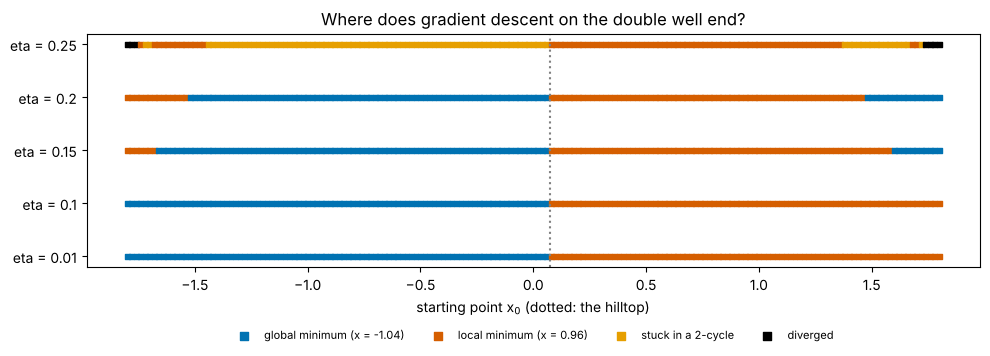

In [10]:
E = lambda x: x**4 - 2 * x**2 + 0.3 * x
dE = lambda x: 4 * x**3 - 4 * x + 0.3
starts = np.linspace(-1.8, 1.8, 181)
etas_dw = [0.01, 0.1, 0.15, 0.2, 0.25]
with np.errstate(over='ignore', invalid='ignore'):
    ends = np.array([[gradient_descent(dE, s, e, 3000)[-1] for s in starts] for e in etas_dw])   # (5, 181) end points
def outcome(v):
    if not np.isfinite(v) or abs(v) > 3: return 3                 # diverged
    if abs(v + 1.0356) < 1e-3: return 0                           # global minimum
    if abs(v - 0.9601) < 1e-3: return 1                           # local minimum
    return 2                                                      # still moving: a cycle
OUT_COL = [PALETTE[0], PALETTE[1], PALETTE[4], 'black']
OUT_LAB = ['global minimum (x = -1.04)', 'local minimum (x = 0.96)', 'stuck in a 2-cycle', 'diverged']
fig, ax = plt.subplots(figsize=(10, 3.8))
for i, eta in enumerate(etas_dw):
    oc = np.array([outcome(v) for v in ends[i]])
    ax.scatter(starts, np.full(starts.size, i), c=[OUT_COL[o] for o in oc], s=12, marker='s')
    hill_rule = (starts > 0.0754).astype(int)
    print(f"eta = {eta:<5}: global {np.sum(oc == 0):3d}, local {np.sum(oc == 1):3d}, 2-cycle {np.sum(oc == 2):3d}, diverged {np.sum(oc == 3):2d};  "
          f"converged runs that disagree with the 'which side of the hill' rule: {np.sum((oc < 2) & (oc != hill_rule))}")
ax.set_yticks(range(len(etas_dw))); ax.set_yticklabels([f'eta = {e}' for e in etas_dw])
ax.axvline(0.0754, color='grey', ls=':')
for col, lab in zip(OUT_COL, OUT_LAB):
    ax.scatter([], [], color=col, marker='s', label=lab)
ax.set_xlabel('starting point x$_0$ (dotted: the hilltop)'); ax.set_title('Where does gradient descent on the double well end?')
ax.legend(fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.22), ncol=4, frameon=False)
plt.tight_layout(); plt.show()

With small learning rates the boundary between the two outcomes is the hilltop, exactly as Lesson 11 predicted. From $\eta = 0.15$ on, steps taken on the steep outer walls ($E'' = 12x^2 - 4$ reaches 35 at $|x| = 1.8$) are so long that they jump over the hill, and the outcome no longer follows "which side of the hill did you start on". At $\eta = 0.25$ the **left** valley itself becomes unstable: its curvature is 8.87, so its limit $2/E'' = 0.225$ is exceeded, and runs that reach it bounce in a 2-cycle around it instead of settling; the right valley (curvature 7.06, limit 0.283) is still stable. The learning rate can decide **which** minimum is found, and even make a minimum unreachable.

# **Part 4: Stochastic Gradients, Noise, Schedules and Reproducibility**

When the loss is an average over $n$ data points, $L(\theta) = \frac1n\sum_i \ell_i(\theta)$, each full gradient costs $n$ evaluations. **Stochastic gradient descent (SGD)** instead estimates the gradient from a random **minibatch** $\mathcal{B}$ of $B$ points:

$$g_k = \frac1B\sum_{i\in\mathcal{B}_k}\ell_i'(\theta_k),\qquad \theta_{k+1} = \theta_k - \eta_k\,g_k .$$

- The estimate is **unbiased**: on average over random batches, $g_k$ equals the full gradient.
- It is **noisy**: its variance is $\sigma_g^2/B$, where $\sigma_g^2$ is the variance of the per-point gradients. Larger batches give cleaner but more expensive steps.
- With a **constant** learning rate, SGD never settles: near the minimum the true slope is small but the noise is not, so $\theta$ keeps jittering around $\theta^*$. For a quadratic of curvature $a$ and small $\eta$, the jitter has standard deviation about

$$\operatorname{sd}(\theta) \approx \sqrt{\frac{\eta\,\sigma_g^2}{2aB}},$$

  so halving it needs a 4-fold smaller $\eta$ or a 4-fold larger batch.
- A **decaying schedule** removes the jitter: large steps early (fast progress), small steps late (averaging out the noise). Common choices are $\eta_k = \eta_0/(1 + k/\tau)$, step decay (divide $\eta$ by 10 every so many epochs), and cosine schedules. Convergence to the exact minimum is guaranteed when $\sum_k\eta_k = \infty$ (the steps can travel any distance) and $\sum_k\eta_k^2 < \infty$ (the noise they inject is finite): the **Robbins–Monro** conditions (1951), satisfied by $\eta_k \propto 1/k$.

**Reproducibility.** An SGD run depends on the random batch order. Use an explicit generator (`rng = np.random.default_rng(seed)`), pass it to everything random, and record the seed, the schedule and the batch size with the result. Then the same seed reproduces the run exactly, and **different seeds show how much the answer depends on luck**, which is part of the result.

curvature a = 0.775; per-trial gradient SD at w* = 0.868


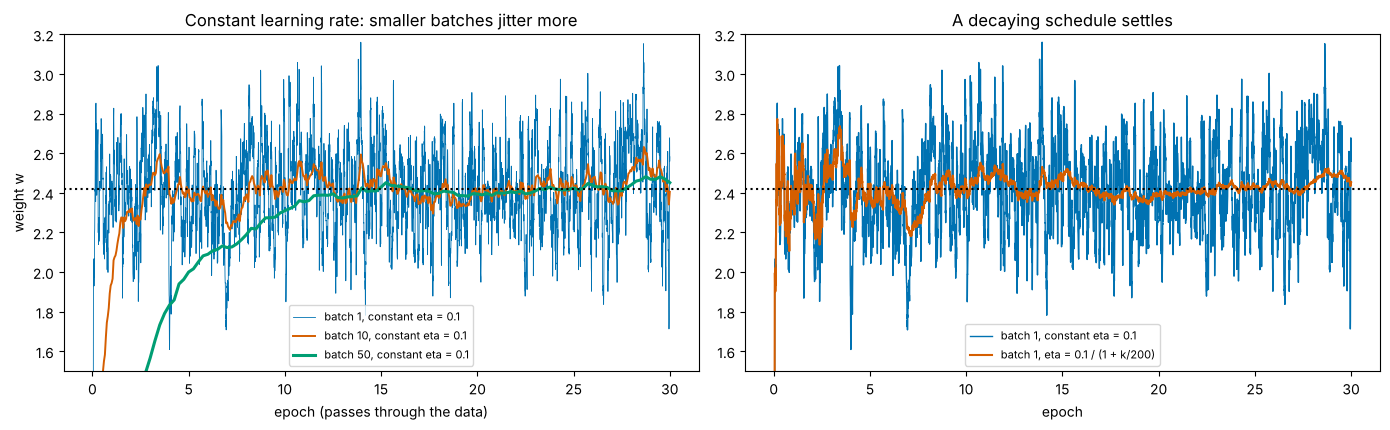

batch  1: SD of w over the last 10 epochs (10 seeds) = 0.2330;  prediction sqrt(eta sigma^2 / (2 a B)) = 0.2204
batch 10: SD of w over the last 10 epochs (10 seeds) = 0.0666;  prediction sqrt(eta sigma^2 / (2 a B)) = 0.0697
batch 50: SD of w over the last 10 epochs (10 seeds) = 0.0295;  prediction sqrt(eta sigma^2 / (2 a B)) = 0.0312


In [11]:
def sgd_gain(B, eta0, tau=None, epochs=3, seed=0):
    # SGD on the gain problem of Part 1 with batch size B; returns the path of w, one value per step.
    rng = np.random.default_rng(seed)
    w, k, path = 0.0, 0, [0.0]
    for _ in range(epochs * (n_trials // B)):                 # one epoch = n / B steps
        b = rng.integers(0, n_trials, B)                     # a random minibatch, drawn with replacement
        g = -np.mean((y_tr[b] - w * x_tr[b]) * x_tr[b])       # minibatch gradient
        eta = eta0 if tau is None else eta0 / (1 + k / tau)
        w -= eta * g; k += 1; path.append(w)
    return np.array(path)

per_point = -(y_tr - w_star * x_tr) * x_tr                    # (200,) per-trial gradients at the minimum
a_gain = np.mean(x_tr**2)
print(f"curvature a = {a_gain:.3f}; per-trial gradient SD at w* = {per_point.std():.3f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
for B, colour, lw in zip([1, 10, 50], PALETTE, [0.6, 1.4, 2.2]):
    p = sgd_gain(B, 0.1, epochs=30)
    axes[0].plot(np.linspace(0, 30, p.size), p, color=colour, lw=lw, label=f'batch {B}, constant eta = 0.1')
axes[0].axhline(w_star, color='black', ls=':'); axes[0].set_ylim(1.5, 3.2)
axes[0].set_xlabel('epoch (passes through the data)'); axes[0].set_ylabel('weight w'); axes[0].set_title('Constant learning rate: smaller batches jitter more'); axes[0].legend(fontsize=8)
p_c = sgd_gain(1, 0.1, epochs=30); p_d = sgd_gain(1, 0.1, tau=200, epochs=30)
axes[1].plot(np.linspace(0, 30, p_c.size), p_c, color=PALETTE[0], lw=1, label='batch 1, constant eta = 0.1')
axes[1].plot(np.linspace(0, 30, p_d.size), p_d, color=PALETTE[1], lw=1.5, label='batch 1, eta = 0.1 / (1 + k/200)')
axes[1].axhline(w_star, color='black', ls=':'); axes[1].set_ylim(1.5, 3.2)
axes[1].set_xlabel('epoch'); axes[1].set_title('A decaying schedule settles'); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

for B in [1, 10, 50]:
    late = np.concatenate([sgd_gain(B, 0.1, epochs=30, seed=s)[-200 // B * 10:] for s in range(10)])
    print(f"batch {B:2d}: SD of w over the last 10 epochs (10 seeds) = {late.std():.4f};  prediction sqrt(eta sigma^2 / (2 a B)) = {np.sqrt(0.1 * per_point.var() / (2 * a_gain * B)):.4f}")

#### Interactive version: SGD paths from 20 seeds
Each frame shows where 20 runs (seeds 0–19, batch size 1) are after a given number of steps, with a constant learning rate and with a decaying one.

In [12]:
paths_c = np.array([sgd_gain(1, 0.1, epochs=10, seed=s) for s in range(20)])            # (20, 2001)
paths_d = np.array([sgd_gain(1, 0.1, tau=200, epochs=10, seed=s) for s in range(20)])
frames_k = np.unique(np.round(np.geomspace(1, paths_c.shape[1] - 1, 30)).astype(int))
fig_n = go.Figure([go.Scatter(x=np.round(paths_c[:, 0], 4), y=np.zeros(20) + 1, mode='markers', marker=dict(size=10, color=PALETTE[0]), name='constant eta'),
                   go.Scatter(x=np.round(paths_d[:, 0], 4), y=np.zeros(20), mode='markers', marker=dict(size=10, color=PALETTE[1]), name='decaying eta'),
                   go.Scatter(x=[w_star, w_star], y=[-0.5, 1.5], mode='lines', line=dict(color='black', dash='dot'), name='w*')])
fig_n.frames = [go.Frame(name=str(i), traces=[0, 1], data=[go.Scatter(x=np.round(paths_c[:, k], 4)), go.Scatter(x=np.round(paths_d[:, k], 4))],
                         layout=go.Layout(title=f'after {k} steps: spread {paths_c[:, k].std():.3f} (constant) vs {paths_d[:, k].std():.3f} (decaying)')) for i, k in enumerate(frames_k)]
buttons, sliders = play_pause_and_slider(list(frames_k), prefix='step = ', duration=300)
fig_n.update_layout(title=fig_n.frames[0].layout.title.text, xaxis=dict(title='weight w', range=[0, 3.5]), yaxis=dict(tickvals=[0, 1], ticktext=['decaying', 'constant'], range=[-0.5, 1.5]),
                    template='plotly_white', width=850, height=380, updatemenus=buttons, sliders=sliders)
fig_n.show(config=PLOTLY_CONFIG)
print("same seed twice gives identical paths:", np.array_equal(sgd_gain(1, 0.1, seed=7), sgd_gain(1, 0.1, seed=7)))

same seed twice gives identical paths: True


# **Part 5: Mini-Lab — Learning How Strongly a Motor-Cortex Neuron Follows the Wheel**

We fit a one-parameter **Poisson model** (Lesson 10's exercise; Lesson 18) to the spike counts of a mouse motor-cortex neuron recorded while the mouse turned a wheel ([Steinmetz et al., 2019](https://doi.org/10.1038/s41586-019-1787-x); Neuromatch Academy version; the original data are in the public domain, CC0):

$$\lambda_t = \exp(c + w\,x_t),\qquad L(w) = \frac1n\sum_t\big(\lambda_t - y_t\ln\lambda_t\big).$$

- $y_t$: the neuron's spike count in 50 ms bin $t$;
- $x_t$: the wheel **speed** in the same bin, standardised with training statistics, so $x_t > 0$ means "turning faster than average";
- $c = \ln\bar y$: fixed at the log of the training mean count (a simplification: only the **gain** $w$ is learned);
- $w$: how strongly the expected count is modulated by speed; $e^{w}$ is the factor by which it changes per standard deviation of speed.

The loss is convex (Lesson 11): $L'(w) = \frac1n\sum_t(\lambda_t - y_t)\,x_t$ and $L''(w) = \frac1n\sum_t\lambda_t x_t^2 > 0$. But unlike a quadratic, its **curvature changes with $w$**, which turns out to matter for the learning rate. We use neuron 332, the neuron whose rate is most correlated with wheel speed in the training trials (Lessons 8 and 11).

In [13]:
import os, urllib.request

MOP_FILE = 'steinmetz_s10_hench_mop.npz'
for candidate in [MOP_FILE, os.path.join('..', '..', 'data', MOP_FILE)]:   # a local copy, or the repository's data folder
    if os.path.exists(candidate):
        mop_path = candidate
        break
else:
    urllib.request.urlretrieve('https://raw.githubusercontent.com/peter-adepoju/math-neuro-ml/51d88220064023b5d3240c39e19b07acc7896f44/data/' + MOP_FILE, MOP_FILE)
    mop_path = MOP_FILE
mop = np.load(mop_path)
BIN = 0.05                                                              # we use 50 ms bins (5 of the file's 10 ms bins)
n_trials, n_neurons, _ = mop['spikes'].shape
rates_3d = mop['spikes'].reshape(n_trials, n_neurons, 50, 5).sum(axis=3) / BIN   # (342, 447, 50): (trial, neuron, 50 ms bin), spikes/s
wheel_2d = mop['wheel'].reshape(n_trials, 50, 5).sum(axis=2) / BIN                # (342, 50): (trial, 50 ms bin), wheel velocity, encoder steps/s

counts = mop['spikes'].reshape(n_trials, n_neurons, 50, 5).sum(axis=3).transpose(0, 2, 1).reshape(-1, n_neurons).astype(float)   # (17100, 447) spike counts per 50 ms bin
speed_all = np.abs(wheel_2d.reshape(-1))                            # (17100,) wheel speed, encoder steps/s
train = np.repeat(np.arange(n_trials) < n_trials // 2, 50)          # rows of the first 171 trials

NEURON = 332
x_all = (speed_all - speed_all[train].mean()) / speed_all[train].std()   # standardised with training statistics
y_all = counts[:, NEURON]
x_tr5, y_tr5, x_te5, y_te5 = x_all[train], y_all[train], x_all[~train], y_all[~train]
c5 = np.log(y_tr5.mean())
print(f"neuron {NEURON}: mean count {y_tr5.mean():.3f} per bin ({y_tr5.mean() / 0.05:.1f} spikes/s); training bins {x_tr5.size}; "
      f"standardised speed from {x_tr5.min():.2f} to {x_tr5.max():.2f} (skewed: many still bins, a few very fast ones)")

def L5(w, x=x_tr5, y=y_tr5):
    z = c5 + w * x
    return np.mean(np.exp(z) - y * z)
def dL5(w, x=x_tr5, y=y_tr5):
    return np.mean((np.exp(c5 + w * x) - y) * x)
def d2L5(w, x=x_tr5):
    return np.mean(np.exp(c5 + w * x) * x**2)

w5 = 0.0
for _ in range(50):                                                   # Newton's method (Lesson 11) for a reference answer
    w5 -= dL5(w5) / d2L5(w5)
print(f"reference minimiser w* = {w5:.4f} (factor e^w* = {np.exp(w5):.2f} per SD of speed);  training loss {L5(w5):.4f} vs {L5(0):.4f} at w = 0")
print(f"test loss {L5(w5, x_te5, y_te5):.4f} vs {L5(0, x_te5, y_te5):.4f} at w = 0")
print(f"curvature: L''(0) = {d2L5(0):.3f}, L''(w*) = {d2L5(w5):.3f}  ->  stability limits 2/L'': {2 / d2L5(0):.2f} at the start, {2 / d2L5(w5):.2f} at the minimum")

neuron 332: mean count 0.224 per bin (4.5 spikes/s); training bins 8550; standardised speed from -0.59 to 4.50 (skewed: many still bins, a few very fast ones)
reference minimiser w* = 0.7181 (factor e^w* = 2.05 per SD of speed);  training loss 0.3345 vs 0.5586 at w = 0
test loss 0.3185 vs 0.5085 at w = 0
curvature: L''(0) = 0.224, L''(w*) = 1.592  ->  stability limits 2/L'': 8.94 at the start, 1.26 at the minimum


The curvature at the minimum is about 7 times the curvature at the start, because $\lambda_t = e^{c + wx_t}$ grows exponentially for the fast-turning bins (large $x_t$) as $w$ grows. So a learning rate chosen from the curvature **at the start**, $\eta = 1/L''(0) \approx 4.47$, is far beyond the stability limit **at the minimum**, $2/L''(w^*) \approx 1.26$. What happens, for that rate and for a few in between?

eta = 0.314 (0.5 / L''(w*)): last values [0.718 0.718 0.718 0.718]
eta = 0.628 (1 / L''(w*)): last values [0.718 0.718 0.718 0.718]
eta = 1.194 (1.9 / L''(w*)): last values [0.718 0.718 0.718 0.718]
eta = 1.400 (1.4): last values [0.47  0.856 0.47  0.856]
eta = 2.000 (2.0): last values [-0.871  0.299  1.053 -0.871]
eta = 4.472 (1 / L''(0)): last values [   0.       2.12  -252.551]   -> diverged


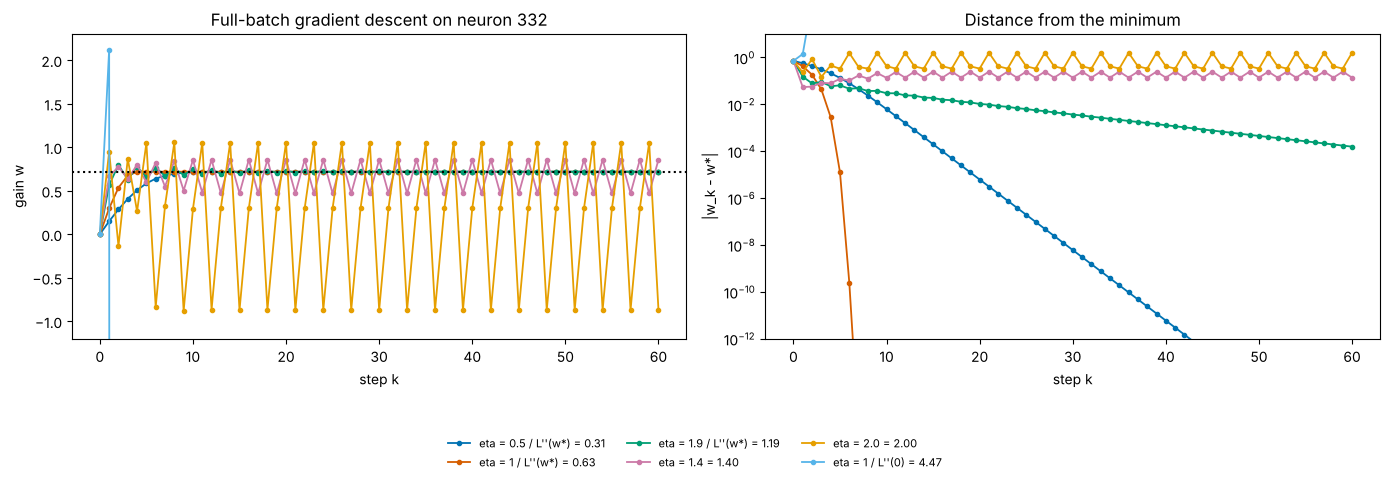

In [14]:
etas5 = {"0.5 / L''(w*)": 0.5 / d2L5(w5), "1 / L''(w*)": 1 / d2L5(w5), "1.9 / L''(w*)": 1.9 / d2L5(w5),
         '1.4': 1.4, '2.0': 2.0, "1 / L''(0)": 1 / d2L5(0)}
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for (name, eta), colour in zip(etas5.items(), PALETTE):
    p = [0.0]
    for _ in range(60):
        with np.errstate(over='ignore', invalid='ignore'):
            p.append(p[-1] - eta * dL5(p[-1]))
        if not np.isfinite(p[-1]) or abs(p[-1]) > 3: break
    p = np.array(p)
    axes[0].plot(p, 'o-', ms=3, lw=1.3, color=colour, label=f'eta = {name} = {eta:.2f}')
    axes[1].semilogy(np.abs(p - w5) + 1e-16, 'o-', ms=3, lw=1.3, color=colour)
    print(f"eta = {eta:.3f} ({name}): last values {np.round(p[-4:], 3)}" + ("   -> diverged" if abs(p[-1]) > 3 or not np.isfinite(p[-1]) else ""))
axes[0].axhline(w5, color='black', ls=':'); axes[0].set_ylim(-1.2, 2.3)
axes[0].set_xlabel('step k'); axes[0].set_ylabel('gain w'); axes[0].set_title(f'Full-batch gradient descent on neuron {NEURON}')
axes[1].set_ylim(1e-12, 10); axes[1].set_xlabel('step k'); axes[1].set_ylabel('|w_k - w*|'); axes[1].set_title('Distance from the minimum')
fig.legend(*axes[0].get_legend_handles_labels(), loc='lower center', ncol=3, fontsize=8, frameon=False)
plt.tight_layout(rect=[0, 0.15, 1, 1]); plt.show()

Four regimes appear:
- **Below the local limit**, the fit converges: monotonically for $\eta = 0.5/L''(w^*)$, in essentially a few steps for $\eta = 1/L''(w^*)$ (the Newton step at the minimum), with damped oscillation for $1.9/L''(w^*)$.
- **Just above it** ($\eta = 1.4$), the fit neither converges nor explodes. It settles into a **two-cycle**, bouncing between about 0.47 and 0.86 forever. On the low side the curvature is smaller and the step is shorter; on the high side it is larger and the step overshoots, and the two balance.
- **Further above** ($\eta = 2.0$) the two-cycle gives way to a **three-cycle**, $-0.87 \to 0.30 \to 1.05 \to -0.87$. A quadratic cannot do any of this; a loss whose curvature changes can.
- **At $\eta = 1/L''(0)$**, a perfectly sensible choice at the start, the first step overshoots to $w \approx 2.1$, where the exponential makes the slope enormous, and the next step throws $w$ far away: divergence.

The lesson: the safe learning rate is set by the **largest curvature the walk will meet**, not the curvature where it starts. Watching the loss, not just $w$, would have caught the cycles: the loss never decreases below a fixed value.

### Stochastic gradients on real data

Now the gradient is estimated from minibatches of bins. We run 20 seeds for each batch size, for 2 epochs, with a constant learning rate and with a decaying one.

per-bin gradient SD at w*: 1.190;  curvature 1.592


batch  10, constant 0.05               : final w over 20 seeds = 0.7097 +- 0.0477   (noise-floor prediction 0.0472)


batch  10, decaying 0.05/(1 + kB/2000) : final w over 20 seeds = 0.7185 +- 0.0138


batch  10, constant 0.01               : final w over 20 seeds = 0.7172 +- 0.0199   (noise-floor prediction 0.0211)
batch 100, constant 0.05               : final w over 20 seeds = 0.7184 +- 0.0130   (noise-floor prediction 0.0149)
batch 100, decaying 0.05/(1 + kB/2000) : final w over 20 seeds = 0.6549 +- 0.0116


batch 100, constant 0.01               : final w over 20 seeds = 0.5784 +- 0.0113   (noise-floor prediction 0.0067)


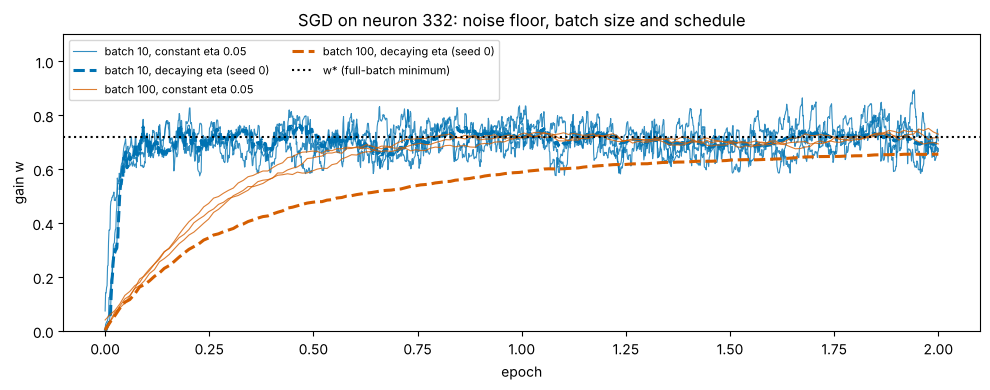

batch 1 with constant eta 0.05: stayed finite; final w 0.066, spread of the last epoch 0.497


In [15]:
def sgd5(B, eta0, tau=None, epochs=2, seed=0):
    rng = np.random.default_rng(seed)
    w, k, path = 0.0, 0, []
    n = x_tr5.size
    for _ in range(epochs * (n // B)):
        b = rng.integers(0, n, B)                                     # random minibatch of bins, with replacement
        eta = eta0 if tau is None else eta0 / (1 + k / tau)
        with np.errstate(over='ignore', invalid='ignore'):
            w -= eta * np.mean((np.exp(c5 + w * x_tr5[b]) - y_tr5[b]) * x_tr5[b])
        k += 1; path.append(w)
    return np.array(path)

g_pts = (np.exp(c5 + w5 * x_tr5) - y_tr5) * x_tr5                  # per-bin gradients at w*
print(f"per-bin gradient SD at w*: {g_pts.std():.3f};  curvature {d2L5(w5):.3f}")
rows = []
for B in [10, 100]:
    for eta0, tau, label in [(0.05, None, 'constant 0.05'), (0.05, 2000 / B, 'decaying 0.05/(1 + kB/2000)'), (0.01, None, 'constant 0.01')]:
        finals = np.array([sgd5(B, eta0, tau, seed=s)[-1] for s in range(20)])
        pred = np.sqrt(eta0 * g_pts.var() / (2 * d2L5(w5) * B)) if tau is None else np.nan
        rows.append((B, label, finals.mean(), finals.std(), pred))
        print(f"batch {B:3d}, {label:<28}: final w over 20 seeds = {finals.mean():.4f} +- {finals.std():.4f}"
              + (f"   (noise-floor prediction {pred:.4f})" if tau is None else ""))

fig, ax = plt.subplots(figsize=(10, 4))
for B, colour in zip([10, 100], [PALETTE[0], PALETTE[1]]):
    for s in range(3):
        p = sgd5(B, 0.05, seed=s)
        ax.plot(np.linspace(0, 2, p.size), p, color=colour, lw=0.8, alpha=0.8, label=f'batch {B}, constant eta 0.05' if s == 0 else None)
    p = sgd5(B, 0.05, tau=2000 / B, seed=0)
    ax.plot(np.linspace(0, 2, p.size), p, color=colour, lw=2.2, ls='--', label=f'batch {B}, decaying eta (seed 0)')
ax.axhline(w5, color='black', ls=':', label='w* (full-batch minimum)')
ax.set_xlabel('epoch'); ax.set_ylabel('gain w'); ax.set_ylim(0, 1.1); ax.set_title(f'SGD on neuron {NEURON}: noise floor, batch size and schedule'); ax.legend(fontsize=8, ncol=2)
plt.tight_layout(); plt.show()
w_b1 = sgd5(1, 0.05, seed=0)
bad = ~np.isfinite(w_b1) | (np.abs(w_b1) > 10)
print(f"batch 1 with constant eta 0.05: " + (f"|w| exceeded 10 at step {int(np.argmax(bad))} and the run then overflowed" if bad.any() else
      f"stayed finite; final w {w_b1[-1]:.3f}, spread of the last epoch {w_b1[w_b1.size // 2:].std():.3f}"))

**Interpretation.**
- **The constant-rate noise floor follows the formula.** With batch 10 and $\eta = 0.05$ the 20 seeds end with a spread of about 0.048, against the predicted $\sqrt{\eta\sigma_g^2/(2aB)} \approx 0.047$; with batch 100 the spread is 0.013 against 0.015.
- **A decaying schedule reduces the spread** at the same cost: with batch 10 it falls from 0.048 to 0.014, and the runs centre on $w^*$. With batch 100 the schedule decays too fast: after only 170 steps the runs average 0.65, still short of $w^* = 0.72$.
- **A smaller constant rate is a trade-off.** With batch 100 and $\eta = 0.01$, the runs have not reached the minimum after 2 epochs (they average 0.58): they are biased towards the start, $w = 0$, and the noise-floor formula does not apply because they are not yet stationary.
- **Batch size 1 is very noisy.** The per-bin gradients are heavy-tailed (a few fast-turning bins with many spikes), so single-bin steps throw $w$ around: over the last epoch the run's spread is about 0.5, and it ends far from $w^*$. Practical remedies are smaller learning rates, gradient clipping, or larger batches.
- **The answer is a distribution over seeds.** Reporting a single SGD run hides its spread; repeated seeds measure it.

**Limitations.** One neuron and a one-parameter model with the baseline $c$ fixed; the neuron was chosen on the same training trials; consecutive 50 ms bins are not independent, so "per-bin gradient variance" understates the true noise of real batches drawn from correlated stretches (random batch order mitigates this here).

# **Part 6: Where This Appears in Neuroscience and Machine Learning**

| Idea | Neuroscience | Machine learning |
|---|---|---|
| Update $\theta \leftarrow \theta - \eta L'$ | delta rule; Rescorla–Wagner learning $V \leftarrow V + \alpha(\lambda - V)$; synaptic plasticity driven by error signals | the core of all neural-network training |
| Learning rate | behavioural learning rates; their adaptation to volatility (faster learning in changing environments) | the most important hyperparameter; warm-up and decay schedules |
| Stability limit $\eta < 2/L''$ | too-fast plasticity destabilises networks; homeostatic mechanisms slow it | "loss explodes": divergence from too large a step; the "edge of stability" |
| Initialisation | developmental starting points; prior biases in learning | weight initialisation (Lesson 10); random restarts |
| Stopping and tolerance | — | early stopping on validation loss; convergence criteria in fitting software |
| Stochastic gradients | trial-by-trial learning from single noisy experiences; synaptic noise | SGD and minibatches; Adam and other adaptive methods; noise as implicit regularisation |
| Schedules | decreasing learning rates with experience (e.g. in perceptual learning) | step, cosine and $1/k$ schedules; Robbins–Monro |
| Reproducibility | seeds of simulations; repeated fits of models to data | seeded runs, reporting the spread over seeds |

**Learning-rate adaptation in the brain.** People adjust how much they learn from each outcome: they learn faster when the environment is volatile and slower when it is stable (Behrens et al., 2007). In the language of this lesson, the brain appears to run something like a learning-rate schedule driven by its estimate of how quickly the target moves.

# **Part 7: Summary and Lesson 13 Preview**

| Idea | Formula / code | What to remember |
|---|---|---|
| Update rule | $\theta_{k+1} = \theta_k - \eta L'(\theta_k)$ | decreases $L$ for small enough $\eta$; stops only at critical points |
| Units of $\eta$ | parameter units$^2$ / loss units | rescaling parameters changes the right $\eta$ |
| Quadratic | $e_{k+1} = (1 - \eta a)\,e_k$ | monotone for $\eta < 1/a$, one step at $1/a$, oscillating up to $2/a$, divergent beyond |
| Stability limit | $\eta < 2/L''$ | set by the **largest** curvature met along the way |
| Convergence speed | $k \approx \ln\varepsilon/\ln\lvert1 - \eta a\rvert$ | linear convergence; sublinear on flat-bottomed losses |
| Stopping | gradient, step, loss-change and validation rules; iteration cap | each can be fooled; report which one stopped the run |
| Initialisation | $\theta_0$ | decides the minimum on non-convex losses |
| SGD | minibatch gradient, unbiased, variance $\sigma_g^2/B$ | constant $\eta$ leaves a noise floor $\approx\sqrt{\eta\sigma_g^2/(2aB)}$ |
| Schedules | $\eta_k = \eta_0/(1 + k/\tau)$, step decay | big steps early, small late; Robbins–Monro conditions |
| Reproducibility | `np.random.default_rng(seed)` | same seed, same run; different seeds measure the luck |

**Lesson 13 — Integration and accumulation.** Gradient descent adds up many small changes: $\theta_k = \theta_0 - \sum_j \eta\,L'(\theta_j)$. Integration is the mathematics of adding up infinitely many infinitely small changes: total charge from a current, total spikes from a rate, area under a curve. Lesson 13 introduces it, and shows that it undoes differentiation.